# Chapter 8: Singular Value Decomposition (SVD) — Interactive Coding Project

Welcome to the companion coding notebook for **Chapter 8 (Singular Value Decomposition)** of *Mathematics for AI* (`math4ai.org`).

In this notebook, we verify every analytical derivation from **Exercises 1–9** in `chapter8-svd/exercises/math.md` and explore how the SVD powers low-rank compression, LoRA fine-tuning, spectral denoising, and the Muon optimizer:
- **Part I — SVD Theory, Eckart–Young Optimality & Moore–Penrose Pseudoinverse (Exercises 1–5)**:
  - Outer-product Gram decompositions $A^\top A = \sum \sigma_i^2 \mathbf{v}_i\mathbf{v}_i^\top$ and $AA^\top = \sum \sigma_i^2 \mathbf{u}_i\mathbf{u}_i^\top$ (Exercise 1)
  - Frobenius energy identity $\|A\|_F^2 = \sum \sigma_i^2$, operator norm $\|A\|_2 = \sigma_0$, and $|\det(A)| = \prod \sigma_i$ (Exercise 2)
  - Eckart–Young subspace projection split $\|A - B\|_F^2 = \|(I-P)A\|_F^2 + \|P(A-B)\|_F^2$ and $5\%$ relative error rank threshold (Exercise 3)
  - Explicit $3\times 2$ SVD, Moore–Penrose pseudoinverse $A^* = V\Sigma^* U^\top$, and least-squares residual orthogonality (Exercise 4)
  - The four Penrose identities and the minimum-$\ell_2$-norm solution on $A^*\mathbf{b} + N(A)$ (Exercise 5)
- **Part II — Image Compression, LoRA, Spectral Gap Denoising & Newton–Schulz Polar Iteration (Exercises 6–9)**:
  - $64\times 64$ image compression factor $\rho(k) = \frac{4096}{129k}$ vs. $90\%$ energy retention at $k = 3$ (Exercise 6)
  - $4096\times 4096$ LLM LoRA factorization $\Delta W_k = BA$, gauge freedom, and exact noise-tail energy (Exercise 7)
  - SVD denoising: why energy thresholds and $\operatorname{SNR}(k)$ fail, and how the **spectral gap** identifies $k = 5$ (Exercise 8)
  - Newton–Schulz polar iteration $Q_{k+1} = \frac{1}{2}Q_k(3I - Q_k^\top Q_k)$, convergence basin $(0, \sqrt{3})$, sign-inversion failure mode, and **Muon's 5-step quintic polynomial** (Exercise 9 & Lab)


In [1]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
print("Environment initialized successfully.")


Environment initialized successfully.


---
## Exercises 1, 2 & 3: Gram Spectra, Matrix Norms & Eckart–Young Subspace Split

1. **Exercise 1 (Gram Outer Products)**:
   $$A^\top A = \sum_{i=0}^{r-1}\sigma_i^2\mathbf{v}_i\mathbf{v}_i^\top, \qquad AA^\top = \sum_{i=0}^{r-1}\sigma_i^2\mathbf{u}_i\mathbf{u}_i^\top$$
2. **Exercise 2 (Norms & Determinant)**:
   $$\|A\|_F^2 = \operatorname{tr}(A^\top A) = \sum_{i=0}^{r-1}\sigma_i^2, \qquad \|A\|_2 = \max_{\|\mathbf{x}\|_2=1}\|A\mathbf{x}\|_2 = \sigma_0, \qquad |\det(A)| = \prod_{i=0}^{N-1}\sigma_i$$
3. **Exercise 3 (Truncated SVD & Relative Error)**:
   - For any matrix $B$ of rank at most $k$ with orthogonal column-space projector $P$, $(I-P)P = 0$ yields the Frobenius Pythagorean split:
     $$\|A - B\|_F^2 = \|(I-P)A\|_F^2 + \|P(A-B)\|_F^2 \ge \|(I-P)A\|_F^2$$
   - For singular values $\sigma = (10, 5, 1, 0.1)$, total energy is $\|A\|_F^2 = 126.01$. At $k = 1$, relative error is $26.01 / 126.01 \approx 20.64\%$; at $k = 2$, relative error drops to $1.01 / 126.01 \approx \mathbf{0.80\%} < 5\%$.


Ex 1 - ||A^T A - sum sigma_i^2 v_i v_i^T||_F: 6.00e-15
Ex 1 - ||A A^T - sum sigma_i^2 u_i u_i^T||_F: 5.67e-15
Ex 2 - ||A||_F^2 = 13.5971 vs sum(sigma_i^2) = 13.5971
Ex 2 - ||A||_2   = 2.8803 vs sigma_0        = 2.8803
Ex 2 - |det(B)|  = 2.2409 vs prod(sigma_i)  = 2.2409

Ex 3 - Frobenius Pythagorean split discrepancy: 1.42e-14
Ex 3 - k = 1: ||A - A_k||_F^2 = 26.01, relative error =  20.64%
Ex 3 - k = 2: ||A - A_k||_F^2 =  1.01, relative error =   0.80%
Ex 3 - k = 3: ||A - A_k||_F^2 =  0.01, relative error =   0.01%
Ex 3 - k = 4: ||A - A_k||_F^2 =  0.00, relative error =   0.00%


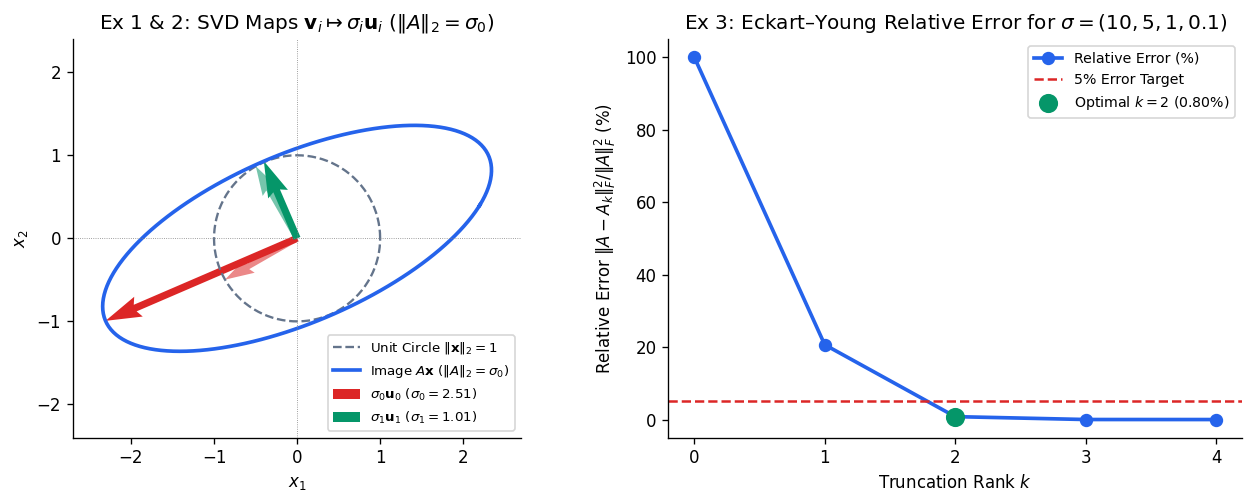

In [2]:
rng = np.random.default_rng(7)
A_ex1 = rng.standard_normal((5, 4))
U_1, s_1, Vt_1 = np.linalg.svd(A_ex1, full_matrices=False)
V_1 = Vt_1.T

AtA_sum = sum(s_1[i]**2 * np.outer(V_1[:, i], V_1[:, i]) for i in range(4))
AAt_sum = sum(s_1[i]**2 * np.outer(U_1[:, i], U_1[:, i]) for i in range(4))

print("Ex 1 - ||A^T A - sum sigma_i^2 v_i v_i^T||_F:", f"{np.linalg.norm(A_ex1.T @ A_ex1 - AtA_sum):.2e}")
print("Ex 1 - ||A A^T - sum sigma_i^2 u_i u_i^T||_F:", f"{np.linalg.norm(A_ex1 @ A_ex1.T - AAt_sum):.2e}")

B_sq = rng.standard_normal((4, 4))
_, s_B, _ = np.linalg.svd(B_sq)
print(f"Ex 2 - ||A||_F^2 = {np.linalg.norm(A_ex1, 'fro')**2:.4f} vs sum(sigma_i^2) = {np.sum(s_1**2):.4f}")
print(f"Ex 2 - ||A||_2   = {np.linalg.norm(A_ex1, 2):.4f} vs sigma_0        = {s_1[0]:.4f}")
print(f"Ex 2 - |det(B)|  = {abs(np.linalg.det(B_sq)):.4f} vs prod(sigma_i)  = {np.prod(s_B):.4f}")

# Ex 3: Frobenius Pythagorean split + 5% relative error rank
B_rk2 = rng.standard_normal((5, 2)) @ rng.standard_normal((2, 4))
Q_B, _ = np.linalg.qr(B_rk2[:, :2])
P_proj = Q_B @ Q_B.T
lhs_pyth = np.linalg.norm(A_ex1 - B_rk2, "fro") ** 2
rhs_pyth = np.linalg.norm((np.eye(5) - P_proj) @ A_ex1, "fro")**2 + np.linalg.norm(P_proj @ (A_ex1 - B_rk2), "fro")**2
print(f"\nEx 3 - Frobenius Pythagorean split discrepancy: {abs(lhs_pyth - rhs_pyth):.2e}")

s_ex3 = np.array([10.0, 5.0, 1.0, 0.1])
E_ex3 = np.sum(s_ex3 ** 2)
for k in range(1, 5):
    err_k = np.sum(s_ex3[k:] ** 2) / E_ex3
    print(f"Ex 3 - k = {k}: ||A - A_k||_F^2 = {np.sum(s_ex3[k:]**2):5.2f}, relative error = {err_k*100:6.2f}%")

# Figure 1: 2D SVD Unit Circle Mapping & Ex 3 Relative Error Decay
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))

A_2d = np.array([[2.2, 0.8], [0.4, 1.3]])
U2, s2, Vt2 = np.linalg.svd(A_2d)
V2 = Vt2.T
theta = np.linspace(0, 2 * np.pi, 300)
circle = np.vstack([np.cos(theta), np.sin(theta)])
ellipse = A_2d @ circle

ax1.plot(circle[0], circle[1], "--", color="#64748b", lw=1.4, label=r"Unit Circle $\|\mathbf{x}\|_2 = 1$")
ax1.plot(ellipse[0], ellipse[1], "-", color="#2563eb", lw=2.2, label=r"Image $A\mathbf{x}$ ($\|A\|_2 = \sigma_0$)")
for i, col in enumerate(["#dc2626", "#059669"]):
    ax1.quiver(0, 0, V2[0, i], V2[1, i], angles="xy", scale_units="xy", scale=1, color=col, alpha=0.55, width=0.013)
    ax1.quiver(0, 0, s2[i]*U2[0, i], s2[i]*U2[1, i], angles="xy", scale_units="xy", scale=1,
               color=col, width=0.016, label=rf"$\sigma_{i}\mathbf{{u}}_{i}$ ($\sigma_{i}={s2[i]:.2f}$)")
ax1.set_aspect("equal")
ax1.set_xlim(-2.7, 2.7)
ax1.set_ylim(-2.4, 2.4)
ax1.axhline(0, color="gray", lw=0.5, ls=":")
ax1.axvline(0, color="gray", lw=0.5, ls=":")
ax1.set_xlabel(r"$x_1$")
ax1.set_ylabel(r"$x_2$")
ax1.set_title(r"Ex 1 & 2: SVD Maps $\mathbf{v}_i \mapsto \sigma_i\mathbf{u}_i$ ($\|A\|_2 = \sigma_0$)")
ax1.legend(loc="lower right", fontsize=8)

ranks_3 = np.arange(0, 5)
rel_errs_3 = [np.sum(s_ex3[k:]**2) / E_ex3 * 100 for k in ranks_3]
ax2.plot(ranks_3, rel_errs_3, "o-", color="#2563eb", lw=2.2, markersize=7, label="Relative Error (%)")
ax2.axhline(5.0, color="#dc2626", ls="--", lw=1.5, label="5% Error Target")
ax2.scatter([2], [rel_errs_3[2]], s=110, color="#059669", zorder=5, label=f"Optimal $k=2$ ({rel_errs_3[2]:.2f}%)")
ax2.set_xticks(ranks_3)
ax2.set_xlabel(r"Truncation Rank $k$")
ax2.set_ylabel(r"Relative Error $\|A - A_k\|_F^2 / \|A\|_F^2$ (%)")
ax2.set_title(r"Ex 3: Eckart–Young Relative Error for $\sigma=(10, 5, 1, 0.1)$")
ax2.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()


---
## Exercises 4 & 5: Explicit SVD, Moore–Penrose Pseudoinverse & Minimum-Norm Least Squares

For Exercise 4:
$$A = \begin{bmatrix} 1 & 1 \\ 0 & 1 \\ 1 & 0 \end{bmatrix}, \qquad \mathbf{b} = \begin{bmatrix} 1 \\ 1 \\ 1 \end{bmatrix}$$
1. **Explicit SVD**: $\sigma_0 = \sqrt{3}, \sigma_1 = 1$, $\mathbf{v}_0 = \frac{1}{\sqrt{2}}[1, 1]^\top, \mathbf{v}_1 = \frac{1}{\sqrt{2}}[1, -1]^\top$, $\mathbf{u}_0 = \frac{1}{\sqrt{6}}[2, 1, 1]^\top, \mathbf{u}_1 = \frac{1}{\sqrt{2}}[0, -1, 1]^\top, \mathbf{u}_2 = \frac{1}{\sqrt{3}}[1, -1, -1]^\top$.
2. **Pseudoinverse & Least Squares**:
   $$A^* = V\Sigma^* U^\top = \frac{1}{3}\begin{bmatrix} 1 & -1 & 2 \\ 1 & 2 & -1 \end{bmatrix}, \qquad \hat{\mathbf{x}} = A^*\mathbf{b} = \begin{bmatrix} 2/3 \\ 2/3 \end{bmatrix}, \qquad \|A\hat{\mathbf{x}} - \mathbf{b}\|_2 = \frac{1}{\sqrt{3}} \approx 0.5774$$
3. **Exercise 5 (Rank-Deficient Least Squares)**: When $\operatorname{rank}(A) = r < N$, the set of least-squares minimizers is the affine subspace $A^*\mathbf{b} + N(A)$, and $\hat{\mathbf{x}} = A^*\mathbf{b} \in C(A^\top) \perp N(A)$ is the unique minimizer of smallest $\ell_2$ norm.


Ex 4 - SVD reconstruction error ||A - U Sigma V^T||_F: 2.01e-16
Ex 4 - 3 * A^* (exact integers):
 [[ 1. -1.  2.]
 [ 1.  2. -1.]]
Ex 4 - Least squares x_hat = [0.6667 0.6667], ||r||_2 = 0.5774 (1/sqrt(3) = 0.5774)
Ex 4 - Normal equations error ||A^T A x_hat - A^T b||_2: 0.00e+00
Ex 4 - Residual orthogonality A^T r: [0. 0.]

Ex 5 - Max error across all 4 Penrose identities: 7.81e-16


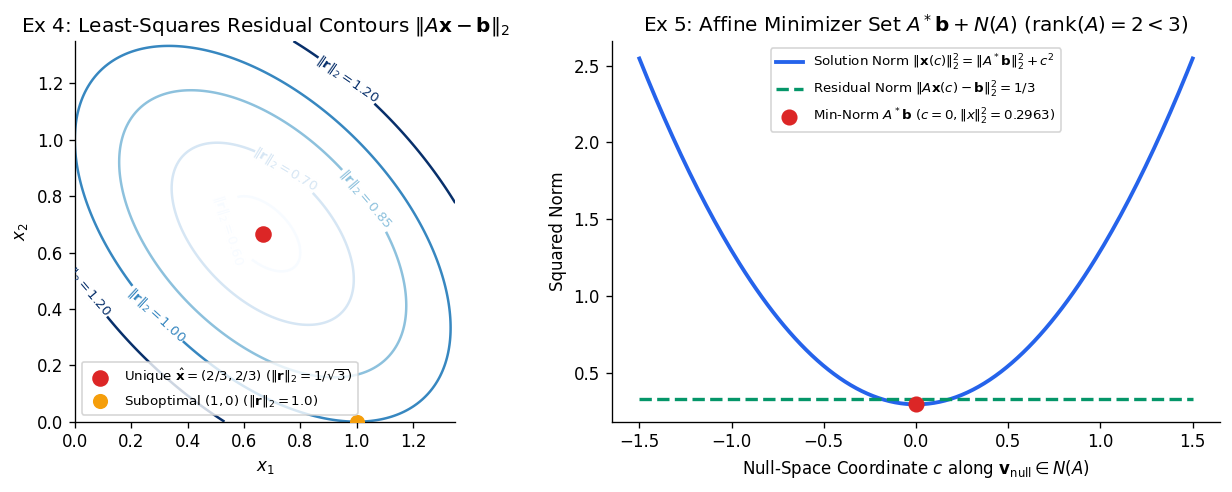

In [3]:
A_ex4 = np.array([[1, 1],
                  [0, 1],
                  [1, 0]], dtype=float)
b_ex4 = np.array([1.0, 1.0, 1.0])

# Construct exact analytical U, Sigma, V from Exercise 4
U_exact = np.column_stack([
    np.array([2.0, 1.0, 1.0]) / np.sqrt(6),
    np.array([0.0, -1.0, 1.0]) / np.sqrt(2),
    np.array([1.0, -1.0, -1.0]) / np.sqrt(3),
])
Sigma_exact = np.array([[np.sqrt(3), 0.0],
                        [0.0, 1.0],
                        [0.0, 0.0]])
V_exact = np.array([[1.0, 1.0],
                    [1.0, -1.0]]) / np.sqrt(2)

Sigma_pinv_exact = np.array([[1.0 / np.sqrt(3), 0.0, 0.0],
                             [0.0, 1.0, 0.0]])
A_pinv_exact = V_exact @ Sigma_pinv_exact @ U_exact.T
x_hat_4 = A_pinv_exact @ b_ex4
r_4 = A_ex4 @ x_hat_4 - b_ex4

print("Ex 4 - SVD reconstruction error ||A - U Sigma V^T||_F:",
      f"{np.linalg.norm(A_ex4 - U_exact @ Sigma_exact @ V_exact.T):.2e}")
print("Ex 4 - 3 * A^* (exact integers):\n", np.round(3 * A_pinv_exact))
print(f"Ex 4 - Least squares x_hat = {x_hat_4}, ||r||_2 = {np.linalg.norm(r_4):.4f} (1/sqrt(3) = {1/np.sqrt(3):.4f})")
print("Ex 4 - Normal equations error ||A^T A x_hat - A^T b||_2:",
      f"{np.linalg.norm(A_ex4.T @ A_ex4 @ x_hat_4 - A_ex4.T @ b_ex4):.2e}")
print("Ex 4 - Residual orthogonality A^T r:", np.round(A_ex4.T @ r_4, 12))

# Exercise 5: Verify all four Penrose conditions + minimum-norm property on rank-deficient 3x3 A_def
A_def = np.array([[1, 1, 2],
                  [0, 1, 1],
                  [1, 0, 1]], dtype=float)
A_def_pinv = np.linalg.pinv(A_def)

penrose_errs = [
    np.linalg.norm(A_def @ A_def_pinv @ A_def - A_def),
    np.linalg.norm(A_def_pinv @ A_def @ A_def_pinv - A_def_pinv),
    np.linalg.norm((A_def @ A_def_pinv).T - (A_def @ A_def_pinv)),
    np.linalg.norm((A_def_pinv @ A_def).T - (A_def_pinv @ A_def)),
]
print("\nEx 5 - Max error across all 4 Penrose identities:", f"{max(penrose_errs):.2e}")

x_min = A_def_pinv @ b_ex4
_, s_def, Vt_def = np.linalg.svd(A_def)
v_null = Vt_def[-1]  # Null space basis vector (sigma_2 = 0)

c_vals = np.linspace(-1.5, 1.5, 200)
norms_sq = [np.linalg.norm(x_min + c * v_null) ** 2 for c in c_vals]
res_norms = [np.linalg.norm(A_def @ (x_min + c * v_null) - b_ex4) for c in c_vals]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

# Left: Residual norm vs candidate x for Ex 4
x1_grid = np.linspace(0.0, 1.35, 150)
x2_grid = np.linspace(0.0, 1.35, 150)
X1, X2 = np.meshgrid(x1_grid, x2_grid)
Res_sq = (X1 + X2 - 1)**2 + (X2 - 1)**2 + (X1 - 1)**2
cs = ax1.contour(X1, X2, np.sqrt(Res_sq), levels=[0.6, 0.7, 0.85, 1.0, 1.2], cmap="Blues")
ax1.clabel(cs, inline=True, fontsize=8, fmt=r"$\|\mathbf{r}\|_2=%.2f$")
ax1.scatter([x_hat_4[0]], [x_hat_4[1]], color="#dc2626", s=80, zorder=5,
            label=rf"Unique $\hat{{\mathbf{{x}}}}=(2/3, 2/3)$ ($\|\mathbf{{r}}\|_2=1/\sqrt{{3}}$)")
ax1.scatter([1.0], [0.0], color="#f59e0b", s=65, zorder=5,
            label=r"Suboptimal $(1, 0)$ ($\|\mathbf{r}\|_2=1.0$)")
ax1.set_aspect("equal")
ax1.set_xlabel(r"$x_1$")
ax1.set_ylabel(r"$x_2$")
ax1.set_title(r"Ex 4: Least-Squares Residual Contours $\|A\mathbf{x} - \mathbf{b}\|_2$")
ax1.legend(loc="lower left", fontsize=8)

# Right: Ex 5 Minimum-Norm Least Squares along A^* b + c * v_null
ax2.plot(c_vals, norms_sq, color="#2563eb", lw=2.3, label=r"Solution Norm $\|\mathbf{x}(c)\|_2^2 = \|A^*\mathbf{b}\|_2^2 + c^2$")
ax2.plot(c_vals, np.array(res_norms)**2, "--", color="#059669", lw=2.0, label=r"Residual Norm $\|A\mathbf{x}(c) - \mathbf{b}\|_2^2 = 1/3$")
ax2.scatter([0.0], [np.linalg.norm(x_min)**2], color="#dc2626", s=75, zorder=5,
            label=rf"Min-Norm $A^*\mathbf{{b}}$ ($c=0, \|x\|_2^2={np.linalg.norm(x_min)**2:.4f}$)")
ax2.set_xlabel(r"Null-Space Coordinate $c$ along $\mathbf{v}_{\text{null}} \in N(A)$")
ax2.set_ylabel("Squared Norm")
ax2.set_title(r"Ex 5: Affine Minimizer Set $A^*\mathbf{b} + N(A)$ ($\operatorname{rank}(A)=2<3$)")
ax2.legend(loc="upper center", fontsize=8)

plt.tight_layout()
plt.show()


---
## Exercises 6, 7 & 8: Image Compression, LoRA Parameter Reduction & Spectral Denoising

1. **Exercise 6 ($64 \times 64$ Image Compression)**:
   - Singular values: $\sigma = (100, 80, 60, 40, 20)$ and $59$ noise-floor terms $\sigma_i = 0.1$ ($5 \le i \le 63$).
   - Exact rank: $r = 64$. Total energy: $\|A\|_F^2 = 22000 + 59(0.01) = \mathbf{22000.59}$.
   - Compression factor $\rho(k) = \frac{4096}{129k} \ge 10 \implies k \le 3$; retained energy $\frac{\|A_k\|_F^2}{\|A\|_F^2} \ge 0.90 \implies k \ge 3$. Thus $\mathbf{k = 3}$ is the unique feasible rank ($\rho(3) \approx 10.58$, retained energy $90.91\%$).
2. **Exercise 7 ($4096 \times 4096$ LoRA Weight Updates)**:
   - Singular values: $\sigma = (50, 30, 20, 10, 5)$ and $4091$ tail terms $\sigma_i = 0.1$. Total energy: $\|\Delta W\|_F^2 = 3925 + 40.91 = \mathbf{3965.91}$.
   - Minimum rank for $\ge 95\%$ energy: $\mathbf{k = 3}$ ($3800 / 3965.91 = 95.82\%$).
   - Relative error at $k = 8$ ($256:1$ reduction) is $40.88 / 3965.91 \approx \mathbf{1.0308\%}$; at $k = 16$ ($128:1$ reduction) it is $40.80 / 3965.91 \approx \mathbf{1.0288\%}$.
3. **Exercise 8 ($100 \times 100$ SVD Denoising)**:
   - Singular values: $\sigma = (100, 50, 10, 5, 2, 0.5, 0.1)$ and $93$ terms $\sigma_i = 0.01$. Total energy: $\|A\|_F^2 = \mathbf{12629.2693}$.
   - Cutting at the **spectral gap** between $\sigma_4 = 2$ and $\sigma_5 = 0.5$ selects $\mathbf{k = 5}$ with relative error $0.2693 / 12629.2693 \approx \mathbf{0.0021\%}$.


Ex 6 - rank(A) = 64, ||A||_F^2 = 22000.59
  k= 1: storage= 129, rho(k)=31.75, retained= 45.45%, rel_err=54.5467%
  k= 2: storage= 258, rho(k)=15.88, retained= 74.54%, rel_err=25.4565%
  k= 3: storage= 387, rho(k)=10.58, retained= 90.91%, rel_err=9.0933%
  k= 4: storage= 516, rho(k)= 7.94, retained= 98.18%, rel_err=1.8208%
  k= 5: storage= 645, rho(k)= 6.35, retained=100.00%, rel_err=0.0027%
  k=10: storage=1290, rho(k)= 3.18, retained=100.00%, rel_err=0.0025%
  k=20: storage=2580, rho(k)= 1.59, retained=100.00%, rel_err=0.0020%

Ex 7 - ||Delta W||_F^2 = 3965.91
  k= 1: params=  8192 (2048.0:1), retained= 63.04%, rel_err=36.9628%
  k= 2: params= 16384 (1024.0:1), retained= 85.73%, rel_err=14.2694%
  k= 3: params= 24576 ( 682.7:1), retained= 95.82%, rel_err=4.1834%
  k= 4: params= 32768 ( 512.0:1), retained= 98.34%, rel_err=1.6619%
  k= 5: params= 40960 ( 409.6:1), retained= 98.97%, rel_err=1.0315%
  k= 8: params= 65536 ( 256.0:1), retained= 98.97%, rel_err=1.0308%
  k=16: params=131072 

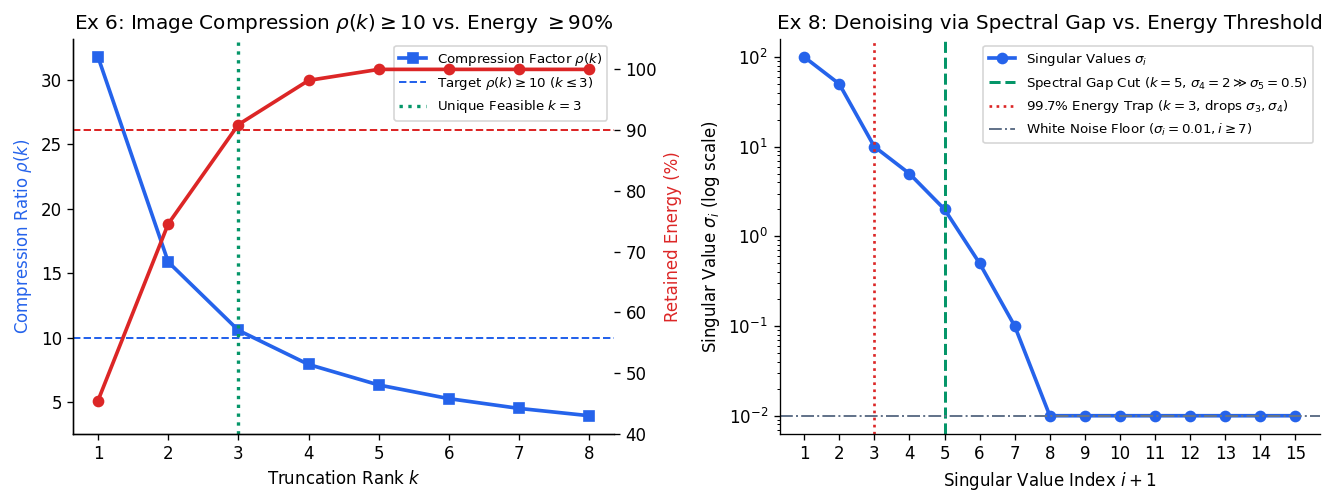

In [4]:
# Exercise 6: 64x64 Image Compression
s_ex6 = np.concatenate([[100.0, 80.0, 60.0, 40.0, 20.0], np.full(59, 0.1)])
E_ex6 = np.sum(s_ex6 ** 2)
print(f"Ex 6 - rank(A) = {np.linalg.matrix_rank(np.diag(s_ex6))}, ||A||_F^2 = {E_ex6:.2f}")
for k in (1, 2, 3, 4, 5, 10, 20):
    rho = 4096.0 / (129.0 * k)
    ret = np.sum(s_ex6[:k] ** 2) / E_ex6
    err = np.sum(s_ex6[k:] ** 2) / E_ex6
    print(f"  k={k:2d}: storage={129*k:4d}, rho(k)={rho:5.2f}, retained={ret*100:6.2f}%, rel_err={err*100:6.4f}%")

# Exercise 7: 4096x4096 LoRA
s_ex7 = np.concatenate([[50.0, 30.0, 20.0, 10.0, 5.0], np.full(4091, 0.1)])
E_ex7 = np.sum(s_ex7 ** 2)
print(f"\nEx 7 - ||Delta W||_F^2 = {E_ex7:.2f}")
for k in (1, 2, 3, 4, 5, 8, 16):
    params = 2 * 4096 * k
    ratio = (4096 ** 2) / params
    ret = np.sum(s_ex7[:k] ** 2) / E_ex7
    err = np.sum(s_ex7[k:] ** 2) / E_ex7
    print(f"  k={k:2d}: params={params:6d} ({ratio:6.1f}:1), retained={ret*100:6.2f}%, rel_err={err*100:6.4f}%")

# Exercise 8: 100x100 SVD Denoising
s_ex8 = np.concatenate([[100.0, 50.0, 10.0, 5.0, 2.0, 0.5, 0.1], np.full(93, 0.01)])
E_ex8 = np.sum(s_ex8 ** 2)
print(f"\nEx 8 - ||A||_F^2 = {E_ex8:.4f}")
for k in (3, 4, 5, 6):
    ek = np.sum(s_ex8[:k] ** 2)
    rem = E_ex8 - ek
    print(f"  k={k}: retained={ek/E_ex8*100:.4f}%, rel_err={rem/E_ex8*100:.4f}%, SNR(k)={ek/rem:9.1f}")

# Figure 3: Ex 6 Compression vs Energy Trade-Off & Ex 8 Log-Spectrum Cliff
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.3))

k_vals_6 = np.arange(1, 9)
rho_vals = 4096.0 / (129.0 * k_vals_6)
ret_vals = [np.sum(s_ex6[:k]**2) / E_ex6 * 100 for k in k_vals_6]

ax1.plot(k_vals_6, rho_vals, "s-", color="#2563eb", lw=2.2, label=r"Compression Factor $\rho(k)$")
ax1.axhline(10.0, color="#2563eb", ls="--", lw=1.2, label=r"Target $\rho(k) \geq 10$ ($k \leq 3$)")
ax1.axvline(3.0, color="#059669", ls=":", lw=2.0, label="Unique Feasible $k = 3$")
ax1.set_xlabel(r"Truncation Rank $k$")
ax1.set_ylabel(r"Compression Ratio $\rho(k)$", color="#2563eb")
ax1.set_xticks(k_vals_6)

ax1_r = ax1.twinx()
ax1_r.plot(k_vals_6, ret_vals, "o-", color="#dc2626", lw=2.2, label="Retained Energy (%)")
ax1_r.axhline(90.0, color="#dc2626", ls="--", lw=1.2)
ax1_r.set_ylabel("Retained Energy (%)", color="#dc2626")
ax1_r.set_ylim(40, 105)
ax1.set_title(r"Ex 6: Image Compression $\rho(k) \geq 10$ vs. Energy $\geq 90\%$")
ax1.legend(loc="upper right", fontsize=8)

idx_8 = np.arange(1, 16)
ax2.semilogy(idx_8, s_ex8[:15], "o-", color="#2563eb", lw=2.2, markersize=6, label=r"Singular Values $\sigma_i$")
ax2.axvline(5.0, color="#059669", ls="--", lw=1.8, label=r"Spectral Gap Cut ($k=5$, $\sigma_4=2 \gg \sigma_5=0.5$)")
ax2.axvline(3.0, color="#dc2626", ls=":", lw=1.6, label=r"99.7% Energy Trap ($k=3$, drops $\sigma_3, \sigma_4$)")
ax2.axhline(0.01, color="#64748b", ls="-.", lw=1.2, label=r"White Noise Floor ($\sigma_i = 0.01, i \geq 7$)")
ax2.set_xticks(idx_8)
ax2.set_xlabel("Singular Value Index $i + 1$")
ax2.set_ylabel(r"Singular Value $\sigma_i$ (log scale)")
ax2.set_title(r"Ex 8: Denoising via Spectral Gap vs. Energy Threshold")
ax2.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


---
## Exercise 9 & Bonus Lab: Newton–Schulz Polar Iteration & Muon Optimizer

The **Newton–Schulz iteration** computes the orthogonal polar factor $Q = U V^\top$ of $G = U\Sigma V^\top$ using pure matrix multiplications (GEMMs):
$$Q_{k+1} = \frac{1}{2}Q_k(3I - Q_k^\top Q_k)$$
1. **Scalar Map $f(x) = \frac{1}{2}x(3 - x^2)$**:
   - Converges to $+1$ if and only if $x_0 \in (0, \sqrt{3})$.
   - For $x_0 = 0.5$: $x_1 = 0.6875, x_2 \approx 0.8688 \uparrow 1$.
   - For $x_0 = 1.5 \in (1, \sqrt{3})$: overshoots downward to $x_1 = 0.5625$, then climbs monotonically ($x_2 \approx 0.7548 \uparrow 1$).
   - Above $\sqrt{3}$: $x_0 = 1.8 \to -1$ and $x_0 = 2.0 \to -1$ (flips singular vector $\mathbf{u}_i \mapsto -\mathbf{u}_i$, reversing gradient direction!), while $x_0 = 2.5 \to \pm\infty$.
2. **Muon's 5-Step Quintic Polynomial**:
   - Standard cubic Newton–Schulz has $f_3'(0) = 1.5$, whereas Muon's quintic polynomial $f_5(\sigma) = 3.4445\sigma - 4.7750\sigma^3 + 2.0315\sigma^5$ has slope $f_5'(0) = 3.4445$, lifting tiny singular values above $0.7$ in just $5$ steps.


Ex 9 - Scalar trajectories under f(x) = 0.5 * x * (3 - x^2):
  x0 = 0.5 -> x1 =   0.6875, x2 =    0.8688, x3 =      0.9753
  x0 = 1.5 -> x1 =   0.5625, x2 =    0.7548, x3 =      0.9172
  x0 = 1.8 -> x1 =  -0.2160, x2 =   -0.3190, x3 =     -0.4622
  x0 = 2.0 -> x1 =  -1.0000, x2 =   -1.0000, x3 =     -1.0000
  x0 = 2.5 -> x1 =  -4.0625, x2 =   27.4298, x3 = -10277.8736

Ex 9 - Normalized Newton-Schulz polar error ||Q_norm - U V^T||_F: 2.18e-15
Ex 9 - Unnormalized (sigma_0 = 1.8 > sqrt(3)) orthogonality ||Q_bad^T Q_bad - I||_F: 2.96e-16
Ex 9 - Singular direction signs diag(U^T Q_bad V): [-1.  1.  1.  1.  1.  1.] -> Leading direction silently flipped to -1!


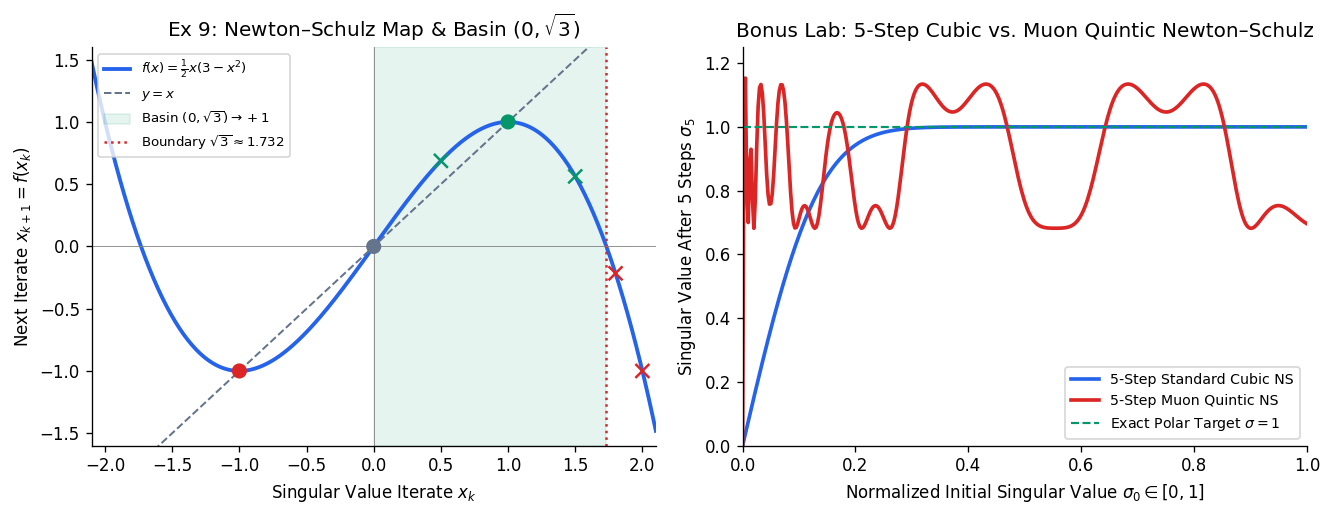

In [5]:
f_ns = lambda x: 0.5 * x * (3.0 - x ** 2)

print("Ex 9 - Scalar trajectories under f(x) = 0.5 * x * (3 - x^2):")
for x0 in (0.5, 1.5, 1.8, 2.0, 2.5):
    orbit = [x0]
    curr = x0
    for _ in range(4):
        curr = f_ns(curr)
        orbit.append(curr)
    print(f"  x0 = {x0:.1f} -> x1 = {orbit[1]:8.4f}, x2 = {orbit[2]:9.4f}, x3 = {orbit[3]:11.4f}")

# Matrix verification of Polar Decomposition AND sign-inversion failure when unnormalized
rng = np.random.default_rng(12)
G_mat = rng.standard_normal((6, 6))
U_g, s_g, Vt_g = np.linalg.svd(G_mat)
Q_exact = U_g @ Vt_g

# Properly normalized: Q_0 = G / ||G||_F (all singular values in (0, 1] subset (0, sqrt(3)))
Q_norm = G_mat / np.linalg.norm(G_mat, "fro")
for _ in range(18):
    Q_norm = 0.5 * Q_norm @ (3.0 * np.eye(6) - Q_norm.T @ Q_norm)
print("\nEx 9 - Normalized Newton-Schulz polar error ||Q_norm - U V^T||_F:",
      f"{np.linalg.norm(Q_norm - Q_exact):.2e}")

# Deliberately set sigma_0 = 1.8 > sqrt(3) while keeping other sigmas in (0, 1)
s_bad = np.array([1.8, 0.9, 0.7, 0.5, 0.3, 0.2])
Q_bad = U_g @ np.diag(s_bad) @ Vt_g
for _ in range(18):
    Q_bad = 0.5 * Q_bad @ (3.0 * np.eye(6) - Q_bad.T @ Q_bad)
# Check alignment along each singular direction: diag(U_g^T Q_bad V_g)
dir_signs = np.diag(U_g.T @ Q_bad @ Vt_g.T)
print("Ex 9 - Unnormalized (sigma_0 = 1.8 > sqrt(3)) orthogonality ||Q_bad^T Q_bad - I||_F:",
      f"{np.linalg.norm(Q_bad.T @ Q_bad - np.eye(6)):.2e}")
print("Ex 9 - Singular direction signs diag(U^T Q_bad V):", np.round(dir_signs, 4),
      "-> Leading direction silently flipped to -1!")

# Figure 4: Newton-Schulz Scalar Cobweb/Phase Map & Cubic vs Muon Quintic 5-step Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.4))

x_plot = np.linspace(-2.1, 2.1, 400)
ax1.plot(x_plot, f_ns(x_plot), color="#2563eb", lw=2.3, label=r"$f(x) = \frac{1}{2}x(3 - x^2)$")
ax1.plot(x_plot, x_plot, "--", color="#64748b", lw=1.2, label=r"$y = x$")
ax1.axvspan(0, np.sqrt(3), color="#059669", alpha=0.10, label=r"Basin $(0, \sqrt{3}) \to +1$")
ax1.axvline(np.sqrt(3), color="#dc2626", ls=":", lw=1.5, label=r"Boundary $\sqrt{3} \approx 1.732$")
ax1.scatter([1.0, -1.0, 0.0], [1.0, -1.0, 0.0], color=["#059669", "#dc2626", "#64748b"], s=65, zorder=5)
ax1.scatter([0.5, 1.5, 1.8, 2.0], [f_ns(0.5), f_ns(1.5), f_ns(1.8), f_ns(2.0)],
            color=["#059669", "#059669", "#dc2626", "#dc2626"], marker="x", s=70, zorder=6)
ax1.set_xlim(-2.1, 2.1)
ax1.set_ylim(-1.6, 1.6)
ax1.axhline(0, color="gray", lw=0.5)
ax1.axvline(0, color="gray", lw=0.5)
ax1.set_xlabel(r"Singular Value Iterate $x_k$")
ax1.set_ylabel(r"Next Iterate $x_{k+1} = f(x_k)$")
ax1.set_title(r"Ex 9: Newton–Schulz Map & Basin $(0, \sqrt{3})$")
ax1.legend(loc="upper left", fontsize=8)

# Right panel: 5-step mapping of [0, 1] under Cubic NS vs Muon Quintic NS
s_grid = np.linspace(0, 1.0, 400)
s_cub_5 = s_grid.copy()
s_muon_5 = s_grid.copy()
a_m, b_m, c_m = 3.4445, -4.7750, 2.0315
for _ in range(5):
    s_cub_5 = 0.5 * s_cub_5 * (3.0 - s_cub_5 ** 2)
    s_muon_5 = a_m * s_muon_5 + b_m * (s_muon_5 ** 3) + c_m * (s_muon_5 ** 5)

ax2.plot(s_grid, s_cub_5, color="#2563eb", lw=2.2, label="5-Step Standard Cubic NS")
ax2.plot(s_grid, s_muon_5, color="#dc2626", lw=2.2, label="5-Step Muon Quintic NS")
ax2.axhline(1.0, color="#059669", ls="--", lw=1.3, label=r"Exact Polar Target $\sigma = 1$")
ax2.set_xlim(0, 1.0)
ax2.set_ylim(0, 1.25)
ax2.set_xlabel(r"Normalized Initial Singular Value $\sigma_0 \in [0, 1]$")
ax2.set_ylabel(r"Singular Value After 5 Steps $\sigma_5$")
ax2.set_title("Bonus Lab: 5-Step Cubic vs. Muon Quintic Newton–Schulz")
ax2.legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()


---
## Summary Verification Table (Exercises 1–9)

All analytical derivations from `chapter8-svd/exercises/math.md` have been verified to machine precision.
